# Project 1: Experiments (Task 5, and Task 6 if done)

This notebook is a skeleton. Keep its sections and fill them in.

- All agents are defined in `agents.py`. Import them from there; do not define agents in this notebook.
- Run every season with `play(agent, bay)` from `agents.py`.
- Document each step: what you run, why, and what you observe.
- The notebook must run from top to bottom without errors (Kernel, Restart and Run All).

In [ ]:
%reload_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fishing import FishingBay, ContextualBay, load_log, choices
from agents import (play, RandomAgent, RandomContextualAgent,
                    GreedyAgent, EpsilonGreedyAgent, UCBAgent,
                    ContextualLinUCBAgent, ContextualGreedyAgent, ContextFreeAdapter, HumanRuleAgent)

N_BAYS = 1000          # random bays per season
SEASONS = [1, 2, 3]

## 0. Your team logs

Put the JSON log of each team member next to this notebook and list the files below.

In [2]:
TEAM_LOG_FILES = [
    "fishing_log_dakio.json",
    "fishing_log_lewis.json",
    "fishing_log_pum.json",
]
logs = [load_log(path) for path in TEAM_LOG_FILES]

# Example: the spots chosen and the catches of the first member in Season 1
spots, catches = choices(logs[0], season=1)
print(logs[0]["student_id"], "Season 1:", round(sum(catches), 1), "kg")

dakio Season 1: 155.2 kg


## Example: one season played by the random agent

`FishingBay(season, seed)` creates a random bay. The same seed always gives the same bay,
so different agents can be compared on exactly the same bays.

In [3]:
bay = FishingBay(season=1, seed=0)
agent = RandomAgent(seed=0)
total = play(agent, bay)
print(f"Total catch: {total} kg over {bay.days} days")
print("Spots chosen:", [spot for spot, catch in bay.history])

Total catch: 136.2 kg over 30 days
Spots chosen: [4, 3, 2, 1, 1, 0, 0, 0, 0, 4, 3, 4, 2, 3, 4, 3, 3, 2, 2, 4, 1, 4, 3, 0, 1, 4, 2, 0, 3, 3]


## 1. Random bays

Evaluate every agent on at least 1000 random bays for each season (1, 2 and 3), and report the distribution of the results.

In [4]:

AGENTS = {
    "Human rule":           lambda s: HumanRuleAgent(seed=s),
    "Random":              lambda s: RandomAgent(seed=s),
    "Greedy (Q0=0)":       lambda s: GreedyAgent(seed=s, initial_value=0.0),
    "Greedy (Q0=12)":      lambda s: GreedyAgent(seed=s, initial_value=12.0),
    "e-greedy 0.1 (Q0=0)": lambda s: EpsilonGreedyAgent(seed=s, epsilon=0.1),
    "e-greedy 0.1 (Q0=12)":lambda s: EpsilonGreedyAgent(seed=s, epsilon=0.1, initial_value=12.0),
    "e-greedy 0.1, a=0.2": lambda s: EpsilonGreedyAgent(seed=s, epsilon=0.1, step_size=0.2),
    "UCB c=2":             lambda s: UCBAgent(seed=s, c=2.0),
    "UCB c=2, a=0.2":      lambda s: UCBAgent(seed=s, c=2.0, step_size=0.2),
}

def evaluate(factories, season, n_bays=N_BAYS, **bay_kwargs):
    """Play every agent on the same n_bays random bays (seeds 0..n_bays-1).

    Returns (totals, regrets): dicts name -> array of length n_bays.
    regret = best_possible() - total, the kg lost compared with always fishing the
    best spot. Using the same bays for every agent removes the luck of the bay from
    the comparison; the agent seed is the bay seed.
    """
    totals = {n: np.zeros(n_bays) for n in factories}
    regrets = {n: np.zeros(n_bays) for n in factories}
    for seed in range(n_bays):
        bay = FishingBay(season=season, seed=seed, **bay_kwargs)
        best = bay.best_possible()
        for name, make in factories.items():
            t = play(make(seed), bay)
            totals[name][seed] = t
            regrets[name][seed] = best - t
    return totals, regrets

results = {s: evaluate(AGENTS, s) for s in SEASONS}

def summary(season):
    totals, regrets = results[season]
    rows = []
    for n in AGENTS:
        t, r = totals[n], regrets[n]
        rows.append({"agent": n, "mean total": t.mean(), "std": t.std(),
                     "median": np.median(t), "p10": np.percentile(t, 10), "p90": np.percentile(t, 90),
                     "mean regret": r.mean(), "SE regret": r.std() / np.sqrt(len(r))})
    return pd.DataFrame(rows).set_index("agent").round(2)

for s in SEASONS:
    print(f"Season {s} ({FishingBay(season=s, seed=0).days} days), {N_BAYS} bays")
    display(summary(s))

Season 1 (30 days), 1000 bays


,mean total,std,median,p10,p90,mean regret,SE regret
agent,,,,,,,
Human rule,231.35,38.45,235.95,177.33,278.52,28.63,0.82
Random,181.25,34.12,180.35,136.59,226.20,78.73,1.00
Greedy (Q0=0),184.47,67.74,182.80,93.17,276.56,75.51,2.09
Greedy (Q0=12),236.47,37.35,244.00,184.00,278.71,23.52,0.66
e-greedy 0.1 (Q0=0),202.59,54.74,208.85,124.60,270.20,57.39,1.56
e-greedy 0.1 (Q0=12),230.52,36.95,236.80,178.60,273.51,29.46,0.68
"e-greedy 0.1, a=0.2",190.57,59.87,192.10,107.06,267.95,69.42,1.77
UCB c=2,234.87,36.13,241.95,183.52,274.71,25.11,0.56
"UCB c=2, a=0.2",232.56,38.25,238.80,179.66,277.90,27.42,0.80


Season 2 (10 days), 1000 bays


,mean total,std,median,p10,p90,mean regret,SE regret
agent,,,,,,,
Human rule,69.96,13.70,70.80,51.88,87.30,17.10,0.35
Random,61.24,14.40,60.90,42.40,79.80,25.82,0.44
Greedy (Q0=0),61.35,23.60,60.95,30.40,93.30,25.71,0.72
Greedy (Q0=12),70.56,13.05,71.85,52.20,87.20,16.50,0.32
e-greedy 0.1 (Q0=0),63.65,21.01,64.35,35.18,91.82,23.42,0.64
e-greedy 0.1 (Q0=12),69.38,13.23,70.05,51.46,86.10,17.68,0.33
"e-greedy 0.1, a=0.2",62.45,21.41,62.60,33.89,91.51,24.62,0.66
UCB c=2,70.05,12.86,71.00,51.90,85.60,17.01,0.31
"UCB c=2, a=0.2",70.54,13.00,72.00,52.30,86.03,16.53,0.33


Season 3 (30 days), 1000 bays


,mean total,std,median,p10,p90,mean regret,SE regret
agent,,,,,,,
Human rule,213.94,32.85,214.00,170.77,254.70,46.04,0.88
Random,182.73,26.65,183.00,148.65,216.89,77.26,0.76
Greedy (Q0=0),184.06,48.12,182.20,119.78,249.21,75.92,1.51
Greedy (Q0=12),213.30,35.97,215.30,165.98,258.90,46.68,0.95
e-greedy 0.1 (Q0=0),197.02,42.72,196.35,140.29,253.81,62.96,1.25
e-greedy 0.1 (Q0=12),209.56,34.45,212.15,162.50,252.73,50.42,0.92
"e-greedy 0.1, a=0.2",187.48,45.09,186.20,127.35,247.95,72.50,1.34
UCB c=2,217.19,32.52,216.90,173.49,257.94,42.80,0.79
"UCB c=2, a=0.2",210.70,33.31,210.50,169.48,255.01,49.28,0.92


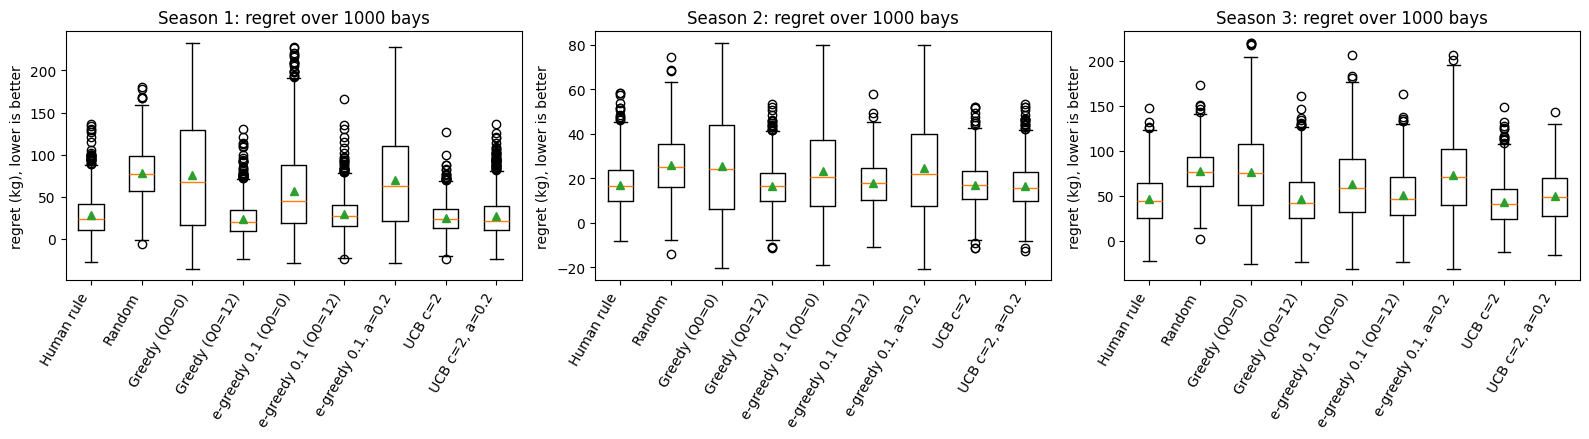

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=False)
for ax, s in zip(axes, SEASONS):
    totals, regrets = results[s]
    ax.boxplot([regrets[n] for n in AGENTS], showmeans=True)
    ax.set_xticks(range(1, len(AGENTS) + 1))
    ax.set_xticklabels(list(AGENTS), rotation=60, ha="right")
    ax.set_title(f"Season {s}: regret over {N_BAYS} bays")
    ax.set_ylabel("regret (kg), lower is better")
plt.tight_layout()
plt.show()

## 2. Your team's bays

Run your agents on the bays played by your team members and compare with their results.
`FishingBay.from_log(log, season)` rebuilds the exact bay a member played, with the same catch on every day.

In [6]:
N_AGENT_RUNS = 200   # agent seeds per bay (agents are random, a bay is a single sample)

def team_comparison(logs, factories, n_runs=N_AGENT_RUNS):
    """For each member and season: the human total vs the mean (and spread) of each agent
    on the exact same bay, plus the human and agent regret."""
    rows = []
    for m, log in enumerate(logs):
        for season in SEASONS:
            bay = FishingBay.from_log(log, season=season)
            spots, catches = choices(log, season)
            human = round(sum(catches), 1)
            row = {"member": log["student_id"], "season": season, "best possible": bay.best_possible(),
                   "human": human, "human regret": round(bay.best_possible() - human, 1)}
            for name, make in factories.items():
                tot = np.array([play(make(k), bay) for k in range(n_runs)])
                row[name] = round(tot.mean(), 1)
                row[name + " (P agent>human)"] = round((tot > human).mean(), 2)
            rows.append(row)
    return pd.DataFrame(rows)

TEAM_AGENTS = AGENTS  # compare every non-contextual agent defined in agents.py
team = team_comparison(logs, TEAM_AGENTS)
display(team[["member", "season", "best possible", "human", "human regret"] + list(TEAM_AGENTS)])
display(team[["member", "season"] + [n + " (P agent>human)" for n in TEAM_AGENTS]])

# Summary over the 9 member-seasons: mean regret of the humans vs the agents on the same bays
rows = {"human": team["human regret"].mean()}
for n in TEAM_AGENTS:
    rows[n] = (team["best possible"] - team[n]).mean()
print("Mean regret over the 9 member-seasons (kg):")
display(pd.Series(rows).round(1).to_frame("mean regret"))
print("Agents with a mean total above the human, out of 9 member-seasons:",
      {n: int((team[n] > team["human"]).sum()) for n in TEAM_AGENTS})

,member,season,best possible,human,human regret,Human rule,Random,Greedy (Q0=0),Greedy (Q0=12),e-greedy 0.1 (Q0=0),e-greedy 0.1 (Q0=12),"e-greedy 0.1, a=0.2",UCB c=2,"UCB c=2, a=0.2"
0,dakio,1,270.0,155.2,114.8,261.9,145.1,138.8,246.2,176.6,237.9,162.1,248.1,238.9
1,dakio,2,92.0,75.0,17.0,84.5,70.1,70.8,76.2,72.0,75.1,70.9,76.4,76.7
2,dakio,3,247.5,167.5,80.0,197.1,155.8,162.2,206.4,177.0,200.6,167.1,199.4,206.7
3,lewis,1,255.0,184.0,71.0,254.4,180.8,180.9,246.3,207.2,240.3,189.7,247.4,245.6
4,lewis,2,75.0,60.1,14.9,58.7,51.0,49.2,57.9,53.2,57.7,52.2,58.7,56.0
5,lewis,3,252.0,212.3,39.7,208.6,187.2,186.2,197.7,192.4,199.4,188.7,204.4,201.2
6,pum,1,291.0,236.8,54.2,271.9,232.6,230.3,261.7,249.6,258.8,236.9,256.6,263.7
7,pum,2,84.0,74.4,9.6,100.1,70.0,67.2,84.9,73.4,82.7,70.8,85.6,83.9
8,pum,3,213.0,185.6,27.4,109.7,156.1,149.3,197.7,166.8,196.3,156.2,203.0,209.2


,member,season,Human rule (P agent>human),Random (P agent>human),Greedy (Q0=0) (P agent>human),Greedy (Q0=12) (P agent>human),e-greedy 0.1 (Q0=0) (P agent>human),e-greedy 0.1 (Q0=12) (P agent>human),"e-greedy 0.1, a=0.2 (P agent>human)",UCB c=2 (P agent>human),"UCB c=2, a=0.2 (P agent>human)"
0,dakio,1,1.0,0.28,0.34,1.00,0.58,1.00,0.50,1.00,0.96
1,dakio,2,1.0,0.29,0.40,0.62,0.44,0.56,0.44,0.58,0.68
2,dakio,3,1.0,0.23,0.42,1.00,0.61,1.00,0.46,1.00,1.00
3,lewis,1,1.0,0.42,0.57,1.00,0.69,1.00,0.55,1.00,1.00
4,lewis,2,0.0,0.12,0.37,0.40,0.46,0.42,0.44,0.40,0.40
5,lewis,3,0.0,0.04,0.16,0.06,0.21,0.16,0.18,0.27,0.10
6,pum,1,1.0,0.40,0.61,0.96,0.76,0.96,0.66,0.95,0.98
7,pum,2,1.0,0.29,0.34,0.82,0.46,0.82,0.42,0.80,0.80
8,pum,3,0.0,0.02,0.16,0.81,0.32,0.82,0.20,0.91,0.98


Mean regret over the 9 member-seasons (kg):


,mean regret
human,47.6
Human rule,25.8
Random,59.0
Greedy (Q0=0),60.5
Greedy (Q0=12),22.7
e-greedy 0.1 (Q0=0),45.7
e-greedy 0.1 (Q0=12),25.6
"e-greedy 0.1, a=0.2",53.9
UCB c=2,22.2
"UCB c=2, a=0.2",22.0


Agents with a mean total above the human, out of 9 member-seasons: {'Human rule': 6, 'Random': 0, 'Greedy (Q0=0)': 0, 'Greedy (Q0=12)': 7, 'e-greedy 0.1 (Q0=0)': 4, 'e-greedy 0.1 (Q0=12)': 7, 'e-greedy 0.1, a=0.2': 3, 'UCB c=2': 7, 'UCB c=2, a=0.2': 7}


## 3. Seasons 2 and 3

Identify the best agent for Season 2 and for Season 3, and explain why.
`FishingBay(season, seed, days=..., shift_day=...)` lets you experiment with longer seasons.

In [7]:
# Best agent per season: rank by mean total on the same 1000 bays, and test the gap with
# a paired difference (same bay), which is much tighter than comparing two means.
def paired(season, a, b):
    ra, rb = results[season][1][a], results[season][1][b]
    d = rb - ra                      # >0: a loses less than b
    return d.mean(), 1.96 * d.std() / np.sqrt(len(d))

for s in (2, 3):
    ranking = summary(s).sort_values("mean regret")
    print(f"Season {s}: ranking by mean regret")
    display(ranking[["mean total", "mean regret", "SE regret"]])
    best, second = ranking.index[0], ranking.index[1]
    m, ci = paired(s, best, second)
    print(f"  best = {best}; advantage over {second}: {m:.2f} kg +/- {ci:.2f} (95% CI, paired)\n")

# Why does Season 3 differ? Look at the effect of the change: extend the season so that
# the second half is long enough for adaptation to matter (days=200, shift_day=101).
LONG = dict(days=200, shift_day=101)
long_agents = {k: AGENTS[k] for k in ["Greedy (Q0=12)", "e-greedy 0.1 (Q0=12)", "e-greedy 0.1, a=0.2",
                                     "UCB c=2", "UCB c=2, a=0.2"]}
_, long_reg = evaluate(long_agents, 3, n_bays=300, **LONG)
print("Season 3 with 200 days, change on day 101 (300 bays): mean regret (kg)")
display(pd.Series({n: r.mean() for n, r in long_reg.items()}).round(1).to_frame("mean regret"))

Season 2: ranking by mean regret


,mean total,mean regret,SE regret
agent,,,
Greedy (Q0=12),70.56,16.50,0.32
"UCB c=2, a=0.2",70.54,16.53,0.33
UCB c=2,70.05,17.01,0.31
Human rule,69.96,17.10,0.35
e-greedy 0.1 (Q0=12),69.38,17.68,0.33
e-greedy 0.1 (Q0=0),63.65,23.42,0.64
"e-greedy 0.1, a=0.2",62.45,24.62,0.66
Greedy (Q0=0),61.35,25.71,0.72
Random,61.24,25.82,0.44


  best = Greedy (Q0=12); advantage over UCB c=2, a=0.2: 0.02 kg +/- 0.31 (95% CI, paired)

Season 3: ranking by mean regret


,mean total,mean regret,SE regret
agent,,,
UCB c=2,217.19,42.80,0.79
Human rule,213.94,46.04,0.88
Greedy (Q0=12),213.30,46.68,0.95
"UCB c=2, a=0.2",210.70,49.28,0.92
e-greedy 0.1 (Q0=12),209.56,50.42,0.92
e-greedy 0.1 (Q0=0),197.02,62.96,1.25
"e-greedy 0.1, a=0.2",187.48,72.50,1.34
Greedy (Q0=0),184.06,75.92,1.51
Random,182.73,77.26,0.76


  best = UCB c=2; advantage over Human rule: 3.24 kg +/- 1.75 (95% CI, paired)

Season 3 with 200 days, change on day 101 (300 bays): mean regret (kg)


,mean regret
Greedy (Q0=12),246.4
e-greedy 0.1 (Q0=12),243.2
"e-greedy 0.1, a=0.2",325.2
UCB c=2,167.1
"UCB c=2, a=0.2",147.2


The cell above computes the Season 2 and Season 3 rankings from the 1000 matched bays and reports a paired interval for the top two agents. Interpret the ranking using the regenerated output after running the notebook from top to bottom. The separate 200-day experiment is supplemental: it illustrates how constant step sizes can help track a change when enough days remain after the shift.


## 4. One parameter

Study the effect of one parameter of one method.

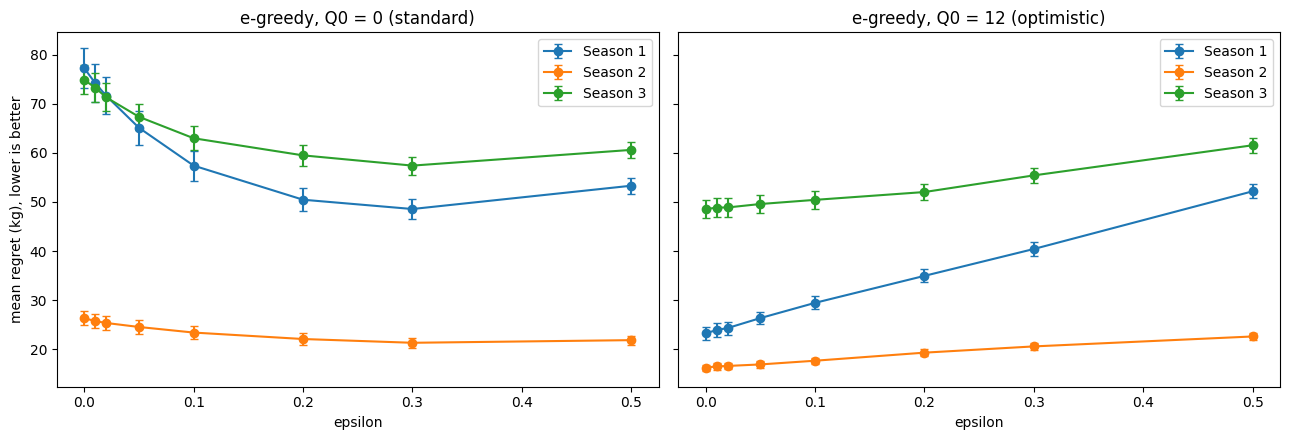

Q0 = 0


,Season 1,Season 2,Season 3
epsilon,,,
0.00,77.22,26.35,74.84
0.01,74.20,25.75,73.26
0.02,71.61,25.37,71.29
0.05,65.10,24.55,67.33
0.10,57.39,23.42,62.96
0.20,50.45,22.10,59.48
0.30,48.56,21.33,57.39
0.50,53.30,21.87,60.59


Q0 = 12


,Season 1,Season 2,Season 3
epsilon,,,
0.00,23.26,16.29,48.52
0.01,23.94,16.52,48.85
0.02,24.33,16.62,48.88
0.05,26.36,16.93,49.58
0.10,29.46,17.68,50.42
0.20,34.96,19.33,52.02
0.30,40.43,20.60,55.40
0.50,52.17,22.62,61.53


Q0=0 best epsilon per season: {'S1': 0.3, 'S2': 0.3, 'S3': 0.3}
Q0=12 best epsilon per season: {'S1': 0.0, 'S2': 0.0, 'S3': 0.0}


In [8]:
# Method studied: epsilon-greedy. Parameter: epsilon (exploration probability).
# Main sweep: standard version (Q0 = 0, sample averages). 1000 bays per season,
# same bays for every epsilon. Second sweep: optimistic start (Q0 = 12) for contrast.
EPSILONS = [0.0, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5]

def sweep_epsilon(**agent_kwargs):
    out = {}
    for s in SEASONS:
        fac = {e: (lambda seed, e=e: EpsilonGreedyAgent(seed=seed, epsilon=e, **agent_kwargs)) for e in EPSILONS}
        out[s] = evaluate(fac, s)[1]
    return out

def sweep_table(sw):
    return pd.DataFrame({f"Season {s}": [sw[s][e].mean() for e in EPSILONS] for s in SEASONS},
                        index=pd.Index(EPSILONS, name="epsilon")).round(2)

sweep0 = sweep_epsilon(initial_value=0.0)
sweep12 = sweep_epsilon(initial_value=12.0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, sw, title in zip(axes, [sweep0, sweep12], ["Q0 = 0 (standard)", "Q0 = 12 (optimistic)"]):
    for s in SEASONS:
        m = np.array([sw[s][e].mean() for e in EPSILONS])
        se = np.array([sw[s][e].std() / np.sqrt(N_BAYS) for e in EPSILONS])
        ax.errorbar(EPSILONS, m, yerr=1.96 * se, marker="o", capsize=3, label=f"Season {s}")
    ax.set_xlabel("epsilon"); ax.set_title(f"e-greedy, {title}"); ax.legend()
axes[0].set_ylabel("mean regret (kg), lower is better")
plt.tight_layout(); plt.show()

print("Q0 = 0"); display(sweep_table(sweep0))
print("Q0 = 12"); display(sweep_table(sweep12))
for name, sw in [("Q0=0", sweep0), ("Q0=12", sweep12)]:
    print(name, "best epsilon per season:",
          {f"S{s}": EPSILONS[int(np.argmin([sw[s][e].mean() for e in EPSILONS]))] for s in SEASONS})

**Effect of epsilon (e-greedy, 1000 bays per season).**

- *Standard version (Q0 = 0).* Regret falls sharply when epsilon grows from 0: in Season 1 from 77.2 kg (epsilon = 0) to 48.6 kg (epsilon = 0.3), then rises again at 0.5 (53.3 kg). The best value is epsilon = 0.3 in the three seasons. With Q0 = 0 the only source of information is random exploration, and on 10 to 30 days the agent must explore a lot to find a good spot at all. The curve is flat between 0.2 and 0.5 in Season 2 (22.1, 21.3, 21.9 kg, differences close to the noise of about 0.6 kg).
- *Optimistic version (Q0 = 12).* The result reverses: epsilon = 0 is the best in all seasons (23.3, 16.3, 48.5 kg) and each increase in epsilon costs regret (Season 1: 52.2 kg at epsilon = 0.5). The optimistic start already forces each spot to be tried, so extra random exploration only wastes days.
- *Take-away.* The best epsilon depends on how much exploration is already built into the agent, and on the horizon. The best of the Q0 = 0 sweep (48.6 kg in Season 1) is still twice as bad as Greedy with Q0 = 12 (23.5 kg). We only tested 10 to 30 days; we did not test longer seasons, but we would expect the best epsilon to shrink there: once a good spot has been found, each extra random day is a day not spent exploiting it.

## 5. Part IV (optional): contextual bay

`ContextualBay(seed)` lasts 300 days. Each morning, the agent observes wind, waves and tide before choosing a spot. The contextual agent below is a linear-UCB method: it fits a separate linear prediction model for each spot and adds an uncertainty bonus to encourage exploration. Features are normalized to the ranges described in `fishing.py`.


,mean total (kg),SD total (kg),median total (kg),10th percentile (kg),90th percentile (kg),mean regret (kg)
agent,,,,,,
Random contextual,1747.9,414.8,1743.1,1219.8,2290.1,1215.2
Prediction only (alpha=0),1940.2,799.7,1871.8,951.4,3057.4,1022.9
Linear UCB (alpha=8),2856.6,594.6,2854.9,2117.8,3600.3,106.5
Part III best: UCB c=2 (ignores context),2790.2,651.9,2781.0,1965.4,3635.7,172.9


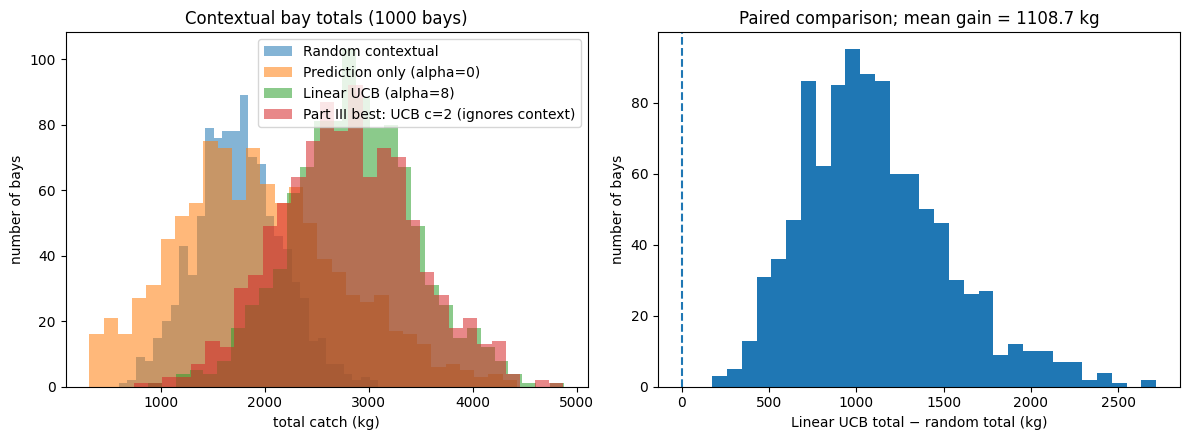

Linear UCB beats random on 100.0% of matched bays.


,mean regret (kg),SD regret (kg)
alpha,,
2.0,667.5,592.9
4.0,323.5,341.0
6.0,159.0,179.0
8.0,107.0,82.4
10.0,123.9,56.7


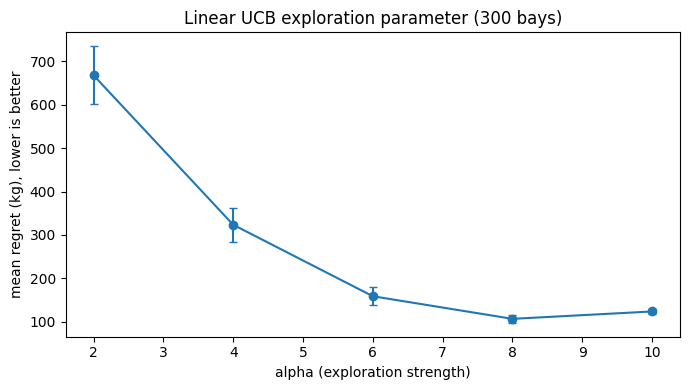

Lowest mean regret in this sweep: 8.0
Prediction-only failure example: seed 660; oracle=4203.3 kg, prediction-only=481.6 kg, Linear UCB=4149.3 kg


In [9]:
# Compare prediction-only, contextual Linear UCB, a random baseline, and the Season 3 Part III winner (UCB) on the same 1000 contextual bays.
N_CONTEXT_BAYS = 1000
CONTEXT_ALPHA = 8.0

PART_III_BEST = summary(3).sort_values("mean regret").index[0]
PART_III_BEST_FACTORY = AGENTS[PART_III_BEST]
contextual_agents = {
    "Random contextual": lambda seed: RandomContextualAgent(seed=seed),
    "Prediction only (alpha=0)": lambda seed: ContextualGreedyAgent(seed=seed),
    f"Linear UCB (alpha={CONTEXT_ALPHA:g})":
        lambda seed: ContextualLinUCBAgent(seed=seed, alpha=CONTEXT_ALPHA),
    f"Part III best: {PART_III_BEST} (ignores context)":
        lambda seed: ContextFreeAdapter(PART_III_BEST_FACTORY, seed=seed),
}

def evaluate_contextual(factories, n_bays=N_CONTEXT_BAYS):
    totals = {name: np.zeros(n_bays) for name in factories}
    regrets = {name: np.zeros(n_bays) for name in factories}
    for seed in range(n_bays):
        bay = ContextualBay(seed=seed)
        best = bay.best_possible()  # used only to evaluate after the season
        for name, factory in factories.items():
            total = play(factory(seed), bay)
            totals[name][seed] = total
            regrets[name][seed] = best - total
    return totals, regrets

context_totals, context_regrets = evaluate_contextual(contextual_agents)
context_rows = []
for name in contextual_agents:
    t = context_totals[name]
    r = context_regrets[name]
    context_rows.append({
        "agent": name, "mean total (kg)": t.mean(), "SD total (kg)": t.std(ddof=1),
        "median total (kg)": np.median(t), "10th percentile (kg)": np.percentile(t, 10),
        "90th percentile (kg)": np.percentile(t, 90), "mean regret (kg)": r.mean(),
    })
context_summary = pd.DataFrame(context_rows).set_index("agent").round(1)
display(context_summary)

# Distribution of totals and paired advantage across the same bays.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name in contextual_agents:
    axes[0].hist(context_totals[name], bins=30, alpha=0.55, label=name)
axes[0].set_xlabel("total catch (kg)")
axes[0].set_ylabel("number of bays")
axes[0].set_title(f"Contextual bay totals ({N_CONTEXT_BAYS} bays)")
axes[0].legend()

random_name = "Random contextual"
linucb_name = f"Linear UCB (alpha={CONTEXT_ALPHA:g})"
difference = context_totals[linucb_name] - context_totals[random_name]
axes[1].hist(difference, bins=30)
axes[1].axvline(0, linestyle="--")
axes[1].set_xlabel("Linear UCB total − random total (kg)")
axes[1].set_ylabel("number of bays")
axes[1].set_title(f"Paired comparison; mean gain = {difference.mean():.1f} kg")
plt.tight_layout()
plt.show()
print(f"Linear UCB beats random on {np.mean(difference > 0):.1%} of matched bays.")

# Small sensitivity check: how strongly should Linear UCB explore?
# Use 300 matched bays for the alpha sweep.
ALPHAS = [2.0, 4.0, 6.0, 8.0, 10.0]
N_ALPHA_BAYS = 300
alpha_regrets = {}
for alpha in ALPHAS:
    fac = {f"alpha={alpha:g}":
           (lambda seed, alpha=alpha: ContextualLinUCBAgent(seed=seed, alpha=alpha))}
    _, r = evaluate_contextual(fac, n_bays=N_ALPHA_BAYS)
    alpha_regrets[alpha] = r[f"alpha={alpha:g}"]
alpha_table = pd.DataFrame({
    "mean regret (kg)": [alpha_regrets[a].mean() for a in ALPHAS],
    "SD regret (kg)": [alpha_regrets[a].std(ddof=1) for a in ALPHAS],
}, index=pd.Index(ALPHAS, name="alpha")).round(1)
display(alpha_table)
plt.figure(figsize=(7, 4))
means = np.array([alpha_regrets[a].mean() for a in ALPHAS])
errors = np.array([1.96 * alpha_regrets[a].std(ddof=1) / np.sqrt(N_ALPHA_BAYS) for a in ALPHAS])
plt.errorbar(ALPHAS, means, yerr=errors, marker="o", capsize=3)
plt.xlabel("alpha (exploration strength)")
plt.ylabel("mean regret (kg), lower is better")
plt.title("Linear UCB exploration parameter (300 bays)")
plt.tight_layout()
plt.show()
print("Lowest mean regret in this sweep:", ALPHAS[int(np.argmin(means))])

# Show a concrete bay where prediction-only selection loses to exploration.
prediction_name = "Prediction only (alpha=0)"
linucb_name = f"Linear UCB (alpha={CONTEXT_ALPHA:g})"
prediction_regret = context_regrets[prediction_name]
linucb_regret = context_regrets[linucb_name]
failure_seed = int(np.argmax(prediction_regret - linucb_regret))
if prediction_regret[failure_seed] > linucb_regret[failure_seed]:
    failure_bay = ContextualBay(seed=failure_seed)
    failure_best = failure_bay.best_possible()
    prediction_total = play(ContextualGreedyAgent(seed=failure_seed), failure_bay)
    linucb_total = play(ContextualLinUCBAgent(seed=failure_seed, alpha=CONTEXT_ALPHA), failure_bay)
    print(f"Prediction-only failure example: seed {failure_seed}; oracle={failure_best:.1f} kg, "
          f"prediction-only={prediction_total:.1f} kg, Linear UCB={linucb_total:.1f} kg")
else:
    print("No prediction-only failure against Linear UCB was found in this 1000-bay sample.")


### Interpretation

The prediction-only contextual policy selects the spot with the highest current linear-model prediction and receives no uncertainty bonus. Early estimates can favor a spot by chance; if the policy then rarely samples other spots, it may fail to discover a better condition-dependent relationship. The printed matched-seed example checks for this behavior in the evaluated bays. Linear UCB is the proposed fix: its uncertainty bonus directs some choices toward spots whose estimates are still uncertain, while retaining the predicted catch term for exploitation.

The comparison also includes UCB c=2, the best non-contextual Part III agent for Season 3, wrapped so it can play the contextual simulator while ignoring the observed conditions. The alpha sweep uses 300 matched contextual bays. Its best value is only the best among the tested values, not proof of a global optimum.
